# Part 1 · Text processing and exploratory data analysis

This notebook goes with the Part 1 report (`reports/part-1/main.tex`), and its
sections follow the report's. Reusable code lives in the package:
`fashion_search.text` turns text into search terms and `fashion_search.corpus`
builds the product records. This notebook runs them, shows the evidence behind
each decision and saves the report's figures to `reports/part-1/figures/`.

Run `uv run python scripts/fetch_data.py` first, then run the notebook top to bottom.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from fashion_search import corpus as cp
from fashion_search.text import build_terms, normalize_text

FIGURES = Path("../reports/part-1/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80)

raw = cp.load_raw()
products = cp.build_corpus(raw)
labels = pd.read_csv("../data/validation_labels.csv")
QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
len(raw), len(products)

(28080, 28080)

## 2. Data preparation

### 2.1 Text pre-processing

`build_terms` applies the same steps to every text field and to queries:

1. **Repair and normalize**: undo UTF-8 text that was decoded as Latin-1
   (`â\x80\x99` back to `’`), fold accents and non-breaking spaces to plain ASCII, lowercase.
2. **Unify spelling variants**: `t-shirt`, `t shirt`, `tshirt`, `tee` → `tshirt`;
   `v-neck` → `vneck`; `slimfit` → `slim fit`.
3. **Remove possessives and join hyphenated words**: `women's` → `women`, `round-neck` → `roundneck`.
4. **Remove punctuation**: every other symbol becomes a space, so `cotton.Designed` splits in two.
5. **Tokenize** with NLTK's `word_tokenize`.
6. **Drop** stop words (NLTK English list), bare numbers and one-letter tokens.
7. **Stem** with the Porter stemmer, as in the practical labs.

In [2]:
examples = [
    "Women's Round-Neck T-Shirt",
    "Slimfit V neck tee",
    "Yorker trackpants made from 100% rich combed cotton.Designed for Comfort,Skin friendly",
    QUERIES[1],
    QUERIES[2],
]
pd.DataFrame({"text": examples, "terms": [build_terms(t) for t in examples]})

,text,terms
0,Women's Round-Neck T-Shirt,"[women, roundneck, tshirt]"
1,Slimfit V neck tee,"[slim, fit, vneck, tshirt]"
2,"Yorker trackpants made from 100% rich combed cotton.Designed for Comfort,Ski...","[yorker, trackpant, made, rich, comb, cotton, design, comfort, skin, friendli]"
3,women full sleeve sweatshirt cotton,"[women, full, sleev, sweatshirt, cotton]"
4,men slim jeans blue,"[men, slim, jean, blue]"


### 2.2 Fields kept for each result

Every result needs `pid, title, description, brand, category, sub_category,
product_details, seller, out_of_stock, selling_price, discount, actual_price,
average_rating, url`. They are all kept in their original form (numbers parsed,
see section 4) next to the term lists. How often each one is present:

In [3]:
present = {}
for field in cp.RESULT_FIELDS:
    col = products[field]
    if field == "product_details":
        present[field] = col.map(len).gt(0).mean()
    else:
        present[field] = col.notna().mean()
pd.Series(present, name="share present").round(3).to_frame()

,share present
pid,1.000
title,1.000
description,0.603
brand,0.928
category,1.000
sub_category,1.000
product_details,1.000
seller,0.941
out_of_stock,1.000
selling_price,1.000


### 2.3 Categorical fields: which to search, and how

Where do the words of the two validation queries appear, in the products
judged relevant? `details` is the values of `product_details` (without the
internal Style Code).

In [4]:
def field_text(row):
    return {
        "title": build_terms(row.title),
        "description": build_terms(row.description),
        "details": build_terms(cp.details_text(row.product_details)),
        "brand": build_terms(row.brand),
        "category": build_terms(f"{row.category} {row.sub_category}"),
    }

raw_by_pid = raw.set_index("pid")
rows = []
for qid, query in QUERIES.items():
    relevant = labels[(labels.query_id == qid) & (labels.labels == 1)].pid
    fields = [field_text(raw_by_pid.loc[p]) for p in relevant]
    for term in build_terms(query):
        for field in ["title", "description", "details", "brand", "category"]:
            share = sum(term in f[field] for f in fields) / len(fields)
            rows.append({"query": qid, "term": term, "field": field, "share": share})
coverage = pd.DataFrame(rows).pivot_table(index=["query", "term"], columns="field", values="share")
coverage = coverage[["title", "description", "details", "brand", "category"]]
coverage.round(2)

field             title  description  details  brand  category
query term                                                    
1     cotton        0.0         0.85     0.85    0.0       0.0
      full          1.0         0.46     1.00    0.0       0.0
      sleev         1.0         0.38     1.00    0.0       0.0
      sweatshirt    1.0         0.69     0.85    0.0       0.0
      women         1.0         0.46     0.31    0.0       0.0
2     blue          1.0         0.30     1.00    0.0       0.0
      jean          1.0         0.60     0.90    0.0       0.0
      men           0.7         0.00     0.70    0.0       0.0
      slim          0.5         0.50     0.10    0.0       0.0

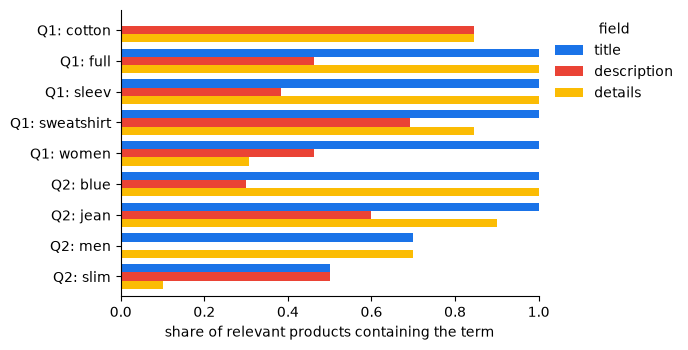

In [5]:
# Brand and category never contain a query term, so only the other three are plotted.
fig, ax = plt.subplots(figsize=(7, 3.6))
coverage[["title", "description", "details"]].plot.barh(ax=ax, width=0.8, color=["#1a73e8", "#ea4335", "#fbbc04"])
ax.invert_yaxis()
ax.set_xlabel("share of relevant products containing the term")
ax.set_ylabel("")
ax.set_yticklabels([f"Q{q}: {t}" for q, t in coverage.index])
ax.set_xlim(0, 1)
ax.legend(title="field", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "query_terms_by_field.pdf")

With conjunctive (AND) queries a product only matches if **every** query term
is in its indexed text. How many relevant products each choice of fields can
still find:

In [6]:
schemes = {
    "title": ["title"],
    "title + description": ["title", "description"],
    "+ details": ["title", "description", "details"],
    "+ details + brand": ["title", "description", "details", "brand"],
    "+ details + brand + category": ["title", "description", "details", "brand", "category"],
}
rows = []
for qid, query in QUERIES.items():
    terms = set(build_terms(query))
    judged = labels[labels.query_id == qid]
    fields = {p: field_text(raw_by_pid.loc[p]) for p in judged.pid}
    for name, used in schemes.items():
        matched = {p for p, f in fields.items() if terms <= {t for u in used for t in f[u]}}
        rel = set(judged[judged.labels == 1].pid)
        rows.append({"query": qid, "fields": name,
                     "relevant matched": f"{len(matched & rel)}/{len(rel)}",
                     "non-relevant matched": f"{len(matched - rel)}/{len(judged) - len(rel)}"})
pd.DataFrame(rows).set_index(["query", "fields"])

relevant matched non-relevant matched
query fields                                                            
1     title                                    0/13                  0/7
      title + description                     11/13                  7/7
      + details                               13/13                  7/7
      + details + brand                       13/13                  7/7
      + details + brand + category            13/13                  7/7
2     title                                    4/10                 1/10
      title + description                      6/10                 2/10
      + details                                6/10                 2/10
      + details + brand                        6/10                 2/10
      + details + brand + category             6/10                 2/10

Category and sub-category never contain a query word and take very few values,
so they work better as filters than as searchable text:

In [7]:
pd.DataFrame({
    "distinct values": {f: products[f].nunique() for f in ["category", "sub_category", "brand", "seller"]},
    "most common share": {f: products[f].value_counts(normalize=True).iloc[0] for f in ["category", "sub_category", "brand", "seller"]},
}).round(3)

,distinct values,most common share
category,4,0.966
sub_category,24,0.545
brand,324,0.036
seller,534,0.053


### 2.4 Numerical fields

Prices, discount and rating arrive as text (`"2,999"`, `"69% off"`, `"3.9"`).
`parse_number` turns them into numbers, keeping missing values as missing
rather than zero. They are not indexed as terms: nobody searches for "921", and
they are more useful as filters and ranking signals.

In [8]:
numeric = ["selling_price", "actual_price", "discount", "average_rating"]
summary = products[numeric].describe().T[["count", "min", "50%", "max"]]
summary["missing"] = products[numeric].isna().sum()
summary.round(2)

,count,min,50%,max,missing
selling_price,28078.0,99.0,545.0,7999.0,2
actual_price,27303.0,150.0,1199.0,12999.0,777
discount,27225.0,1.0,53.0,87.0,855
average_rating,25819.0,1.0,3.8,5.0,2261


In [9]:
# Sanity checks: the parsed discount agrees with the two prices.
has_all = products.dropna(subset=["selling_price", "actual_price", "discount"])
implied = (1 - has_all.selling_price / has_all.actual_price) * 100
print("selling price above actual price:", int((has_all.selling_price > has_all.actual_price).sum()))
print("discount within 1 point of the prices:", round(((implied - has_all.discount).abs() <= 1).mean(), 3))

selling price above actual price: 0
discount within 1 point of the prices: 1.0


### 2.5 Output

The product records are written to `data/processed/products.parquet`
(`uv run python -m fashion_search.corpus` does the same from the command line).
Later parts, and the analysis below, read them with `cp.load_corpus()`.
Every validation product is present.

In [10]:
cp.save_corpus(products)
print("validation products found:", labels.pid.isin(products.pid).sum(), "/", len(labels))
pd.Series({f: len({t for ts in products[f"{f}_terms"] for t in ts}) for f in cp.TEXT_FIELDS}, name="vocabulary").to_frame()

validation products found: 40 / 40


,vocabulary
title,652
description,4933
details,3604
brand,388


## 3. Exploratory data analysis

### 3.1 Text

In [ ]:
# Word count distribution and average sentence length of titles and descriptions,
# vocabulary size (e.g. before and after pre-processing), word clouds,
# entity recognition with spaCy (en_core_web_sm).
# Save figures with fig.savefig(FIGURES / "<name>.pdf").

### 3.2 Catalogue

In [ ]:
# Rankings by rating, price and discount; top sellers and brands; out-of-stock distribution.
# `products` already has numbers parsed; missing values and categories are in 2.2–2.4.

## 4. Conclusions